# Практическая работа №7: Исследовательский анализ данных и базовая визуализация
**Вариант 4**

Задания варианта:
1. Построить scatter plot: `price` vs `revenue`.
2. Посчитать корреляцию между `price` и `revenue`.
3. Построить heatmap корреляций.
4. Найти 10 заказов с максимальной `revenue`.
5. Интерпретировать связь между признаками.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Загрузка данных

In [3]:
orders_files = [
    "data/orders_2024_01.csv",
    "data/orders_2024_02.csv",
    "data/orders_2024_03.csv",
]

df_orders = pd.concat([pd.read_csv(f) for f in orders_files], ignore_index=True)
df_orders["order_datetime"] = pd.to_datetime(df_orders["order_datetime"])
df_orders["revenue"] = df_orders["price"] * df_orders["quantity"]

print(df_orders.head())

   order_id  user_id      order_datetime  product_id     price  quantity  \
0         1     1044 2024-01-03 18:39:26          26  14038.15         1   
1         2     1079 2024-01-03 17:45:43          16   9172.60         1   
2         3     1041 2024-01-06 22:46:38          25   9035.26         2   
3         4     1083 2024-01-08 21:03:51           9  15234.33         3   
4         5     1068 2024-01-03 23:26:53          24   4134.38         2   

     status   revenue  
0  refunded  14038.15  
1      paid   9172.60  
2      paid  18070.52  
3      paid  45702.99  
4      paid   8268.76  


## Задание 1. Scatter plot `price` vs `revenue`

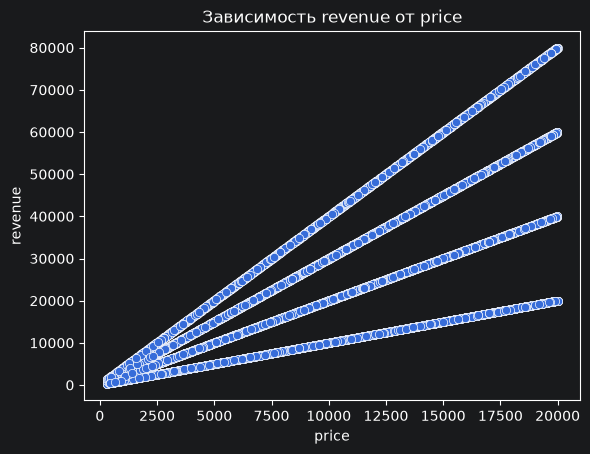

In [4]:
sns.scatterplot(data=df_orders, x="price", y="revenue")
plt.title("Зависимость revenue от price")
plt.show()

## Задание 2. Корреляция между `price` и `revenue`

In [5]:
print("Корреляция price и revenue:", round(df_orders["price"].corr(df_orders["revenue"]), 4))

Корреляция price и revenue: 0.7368


## Задание 3. Heatmap корреляций

             price  quantity   revenue
price     1.000000  0.011629  0.736792
quantity  0.011629  1.000000  0.599920
revenue   0.736792  0.599920  1.000000


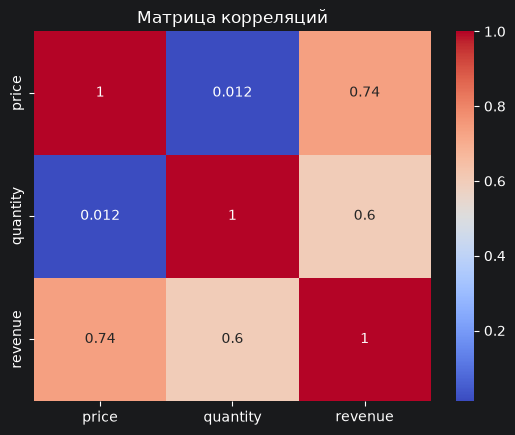

In [6]:
corr = df_orders[["price", "quantity", "revenue"]].corr()
print(corr)

sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Матрица корреляций")
plt.show()

## Задание 4. 10 заказов с максимальной `revenue`

In [7]:
top10_revenue = df_orders.nlargest(10, "revenue")

print(top10_revenue)

       order_id  user_id      order_datetime  product_id     price  quantity  \
2235       2236     1066 2024-01-23 21:37:09          13  19998.96         4   
12443     12444     1064 2024-03-18 06:59:36           9  19982.19         4   
283         284     1065 2024-01-24 08:29:37           1  19976.94         4   
10331     10332     1075 2024-03-30 23:12:55          24  19975.24         4   
2647       2648     1052 2024-01-27 15:18:30          21  19963.54         4   
9106       9107     1064 2024-02-23 06:10:32          12  19959.21         4   
2259       2260     1066 2024-01-01 18:01:53           7  19956.44         4   
10786     10787     1098 2024-03-23 05:28:18          16  19956.04         4   
443         444     1044 2024-01-30 04:39:24          21  19954.05         4   
3914       3915     1012 2024-01-16 20:15:45          18  19943.77         4   

          status   revenue  
2235        paid  79995.84  
12443       paid  79928.76  
283         paid  79907.76  
103

## Задание 5. Интерпретация связи между признаками

1. На scatter plot точки выстраиваются в четыре прямые линии, по одной на каждое значение `quantity` (1–4), потому что `revenue = price × quantity`.
2. Корреляция между `price` и `revenue` равна 0,74: это сильная положительная связь. Чем выше цена, тем больше выручка с заказа.
3. По heatmap `price` и `quantity` между собой почти не связаны (0,01). `quantity` и `revenue` связаны слабее, чем `price` и `revenue` (0,60 против 0,74), поэтому цена влияет на выручку сильнее, чем количество.
4. У всех 10 заказов с максимальной выручкой `quantity = 4` и цена близка к максимальной (около 20 000), поэтому их выручка около 80 000.
5. Связь между `price` и `revenue` не случайная: выручка рассчитывается из цены и количества. Поэтому высокая корреляция здесь ожидаема.